# Task
Analyze the time series data in `quantmod_dataset.csv` by loading and summarizing the data, identifying and inspecting trends, calculating and interpreting autocorrelation and cross-correlation, and performing spectral analysis to identify periodic components. Finally, provide a comprehensive summary of the dataset's characteristics and findings.

## Load and Summarize Data

### Subtask:
Load the `quantmod_dataset.csv` file into a pandas DataFrame. Display its summary information, including the number of observations, variables, their data types, and initial descriptive statistics.


**Reasoning**:
First, I'll import the pandas library to enable data manipulation. Then, I'll load the specified CSV file into a DataFrame. Finally, I'll display the DataFrame's summary information, including data types and non-null values using `.info()`, and then present the descriptive statistics for numerical columns using `.describe()` to meet the subtask requirements.



In [1]:
import pandas as pd

# Load the dataset into a DataFrame
df = pd.read_csv('/content/quantmod_dataset.csv')

# Display a concise summary of the DataFrame
print('DataFrame Info:')
df.info()

# Display descriptive statistics for numerical columns
print('\nDescriptive Statistics:')
df.describe()

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           4024 non-null   object 
 1   GSPC.Open      4024 non-null   float64
 2   GSPC.High      4024 non-null   float64
 3   GSPC.Low       4024 non-null   float64
 4   GSPC.Close     4024 non-null   float64
 5   GSPC.Volume    4024 non-null   float64
 6   GSPC.Adjusted  4024 non-null   float64
 7   IXIC.Open      4024 non-null   float64
 8   IXIC.High      4024 non-null   float64
 9   IXIC.Low       4024 non-null   float64
 10  IXIC.Close     4024 non-null   float64
 11  IXIC.Volume    4024 non-null   float64
 12  IXIC.Adjusted  4024 non-null   float64
dtypes: float64(12), object(1)
memory usage: 408.8+ KB

Descriptive Statistics:


,GSPC.Open,GSPC.High,GSPC.Low,GSPC.Close,GSPC.Volume,GSPC.Adjusted,IXIC.Open,IXIC.High,IXIC.Low,IXIC.Close,IXIC.Volume,IXIC.Adjusted
count,4024.000000,4024.000000,4024.000000,4024.000000,4.024000e+03,4024.000000,4024.000000,4024.000000,4024.000000,4024.000000,4.024000e+03,4024.000000
mean,2944.412381,2960.069326,2927.577092,2945.011381,4.012348e+09,2945.011381,8429.034280,8484.252382,8367.811694,8430.273867,3.360493e+09,8430.273867
std,1490.954940,1498.338506,1482.912188,1491.073720,9.939769e+08,1491.073720,5477.231623,5513.799675,5434.198855,5476.688796,2.583965e+09,5476.688796
min,1027.650024,1032.949951,1010.909973,1022.580017,0.000000e+00,1022.580017,2099.659912,2110.659912,2061.139893,2091.790039,2.214300e+08,2091.790039
25%,1806.299957,1810.665009,1800.722504,1805.630035,3.395712e+09,1805.630035,4065.467407,4085.155029,4040.637390,4062.012512,1.847215e+09,4062.012512
50%,2581.119995,2595.869995,2571.649902,2584.730103,3.834745e+09,2584.730103,6868.479980,6898.425049,6808.864990,6864.919922,2.206095e+09,6864.919922
75%,4076.025024,4098.564941,4052.197571,4078.204956,4.441845e+09,4078.204956,12664.742920,12752.509766,12525.357178,12647.732422,4.591072e+09,12647.732422
max,6936.020020,6945.770020,6921.600098,6932.049805,1.061781e+10,6932.049805,23987.289062,24019.990234,23764.869141,23958.470703,9.397454e+10,23958.470703


## Identify Time Series and Inspect for Trends

### Subtask:
Identify potential time series columns within the dataset. Plot these series to visually inspect for any systematic trends or non-stationary properties. Based on visual inspection, discuss potential detrending methods (e.g., differencing, moving averages) that could be applied, explaining their purpose.


**Reasoning**:
First, I'll convert the 'Date' column to datetime objects to enable proper time series analysis and set it as the DataFrame's index. This is essential for time-based plotting and analysis.



In [2]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date')
print("DataFrame after converting 'Date' to datetime and setting as index:")
df.info()
df.head()

DataFrame after converting 'Date' to datetime and setting as index:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4024 entries, 2010-01-04 to 2025-12-31
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   GSPC.Open      4024 non-null   float64
 1   GSPC.High      4024 non-null   float64
 2   GSPC.Low       4024 non-null   float64
 3   GSPC.Close     4024 non-null   float64
 4   GSPC.Volume    4024 non-null   float64
 5   GSPC.Adjusted  4024 non-null   float64
 6   IXIC.Open      4024 non-null   float64
 7   IXIC.High      4024 non-null   float64
 8   IXIC.Low       4024 non-null   float64
 9   IXIC.Close     4024 non-null   float64
 10  IXIC.Volume    4024 non-null   float64
 11  IXIC.Adjusted  4024 non-null   float64
dtypes: float64(12)
memory usage: 408.7 KB


,GSPC.Open,GSPC.High,GSPC.Low,GSPC.Close,GSPC.Volume,GSPC.Adjusted,IXIC.Open,IXIC.High,IXIC.Low,IXIC.Close,IXIC.Volume,IXIC.Adjusted
Date,,,,,,,,,,,,
2010-01-04,1116.560059,1133.869995,1116.560059,1132.989990,3.991400e+09,1132.989990,2294.409912,2311.149902,2294.409912,2308.419922,1.931380e+09,2308.419922
2010-01-05,1132.660034,1136.630005,1129.660034,1136.520020,2.491020e+09,1136.520020,2307.270020,2313.729980,2295.620117,2308.709961,2.367860e+09,2308.709961
2010-01-06,1135.709961,1139.189941,1133.949951,1137.140015,4.972660e+09,1137.140015,2307.709961,2314.070068,2295.679932,2301.090088,2.253340e+09,2301.090088
2010-01-07,1136.270020,1142.459961,1131.319946,1141.689941,5.270680e+09,1141.689941,2298.090088,2301.300049,2285.219971,2300.050049,2.270050e+09,2300.050049
2010-01-08,1140.520020,1145.390015,1136.219971,1144.979980,4.389590e+09,1144.979980,2292.239990,2317.600098,2290.610107,2317.169922,2.145390e+09,2317.169922


# Task
Plot the 'GSPC.Adjusted' and 'IXIC.Adjusted' time series from the `df` DataFrame to visually inspect for trends and discuss potential detrending methods, such as differencing or moving averages.

## Identify Time Series and Inspect for Trends

### Subtask:
Identify potential time series columns within the dataset. Plot the 'GSPC.Adjusted' and 'IXIC.Adjusted' series to visually inspect for any systematic trends or non-stationary properties. Based on visual inspection, discuss potential detrending methods (e.g., differencing, moving averages) that could be applied, explaining their purpose.


**Reasoning**:
I will import the `matplotlib.pyplot` library and then generate two subplots to visualize the 'GSPC.Adjusted' and 'IXIC.Adjusted' columns from the DataFrame. This will allow for a visual inspection of trends and non-stationary properties as required by the subtask.



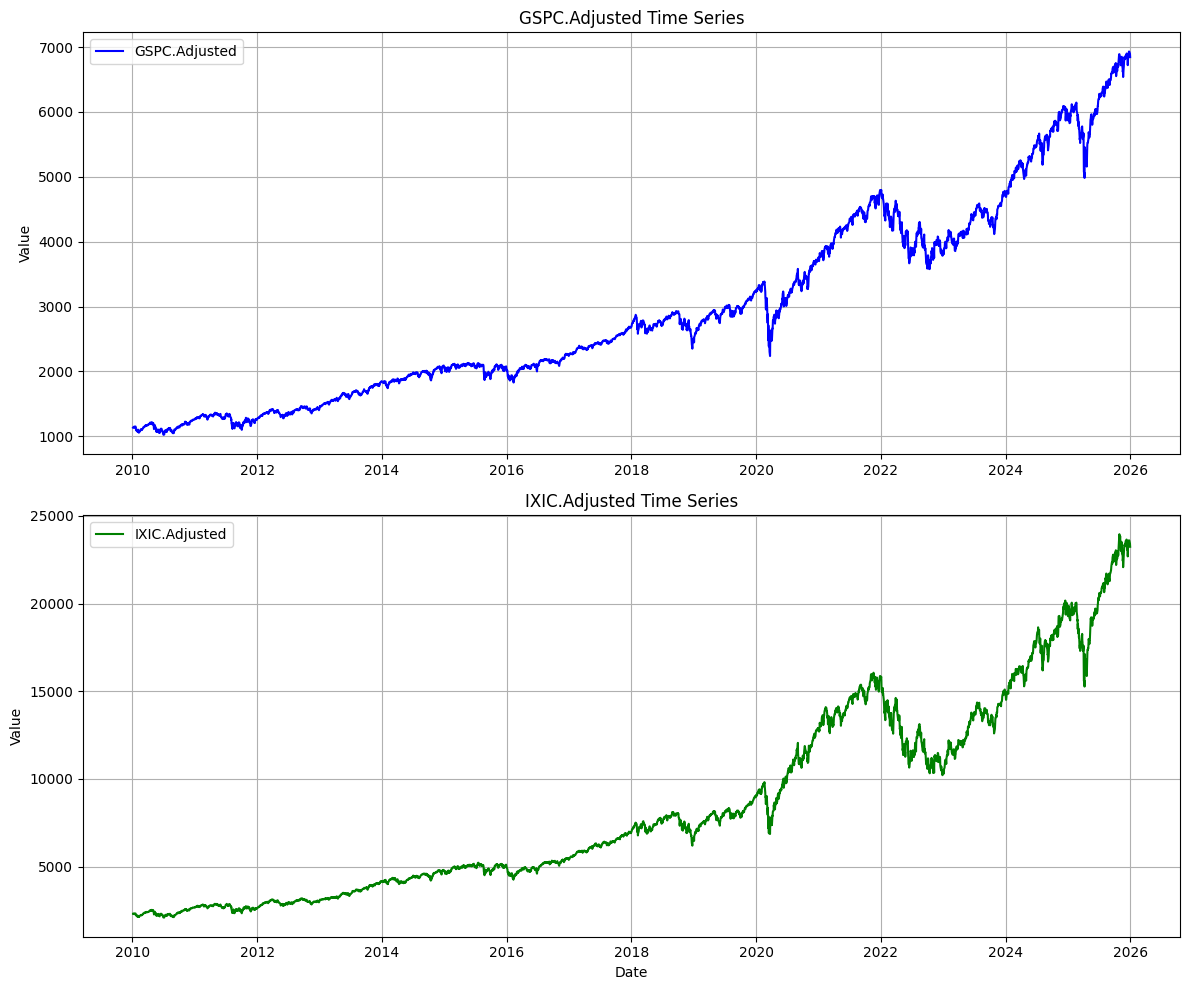

In [3]:
import matplotlib.pyplot as plt

# Create a figure with two subplots
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 10))

# Plot GSPC.Adjusted
axes[0].plot(df.index, df['GSPC.Adjusted'], label='GSPC.Adjusted', color='blue')
axes[0].set_title('GSPC.Adjusted Time Series')
axes[0].set_ylabel('Value')
axes[0].grid(True)
axes[0].legend()

# Plot IXIC.Adjusted
axes[1].plot(df.index, df['IXIC.Adjusted'], label='IXIC.Adjusted', color='green')
axes[1].set_title('IXIC.Adjusted Time Series')
axes[1].set_ylabel('Value')
axes[1].set_xlabel('Date')
axes[1].grid(True)
axes[1].legend()

# Prevent titles and labels from overlapping
plt.tight_layout()

# Display the plots
plt.show()


After visualizing the 'GSPC.Adjusted' and 'IXIC.Adjusted' time series, the following observations can be made:

**Observed Trends:**

Both 'GSPC.Adjusted' (S&P 500) and 'IXIC.Adjusted' (NASDAQ Composite) exhibit a clear **upward trend** over the observed period, indicating general market growth. The series are not constant around a mean value, which suggests they are **non-stationary**. There also appear to be periods of higher volatility (larger fluctuations) at different times, particularly noticeable in the later years of the series for both indices. No obvious strong seasonality (repeating patterns within a fixed period, like annually) is immediately apparent from a visual inspection, which is typical for daily stock market data over several years, although longer-term cycles might exist.

**Potential Detrending Methods:**

To address the observed trends and achieve stationarity (a common requirement for many time series models), detrending methods can be applied:

1.  **Differencing:**
    *   **Purpose:** Differencing involves computing the difference between consecutive observations. First-order differencing (i.e., `Xt - Xt-1`) is commonly used to remove a linear trend. If the trend is more complex (e.g., quadratic), higher-order differencing might be needed. The goal is to make the mean of the series constant over time, removing the upward or downward drift.
    *   **Application:** For these series, first-order differencing would likely be a good starting point to remove the strong upward trend. This would transform the price series into a series of daily price changes or returns.

2.  **Moving Averages (Smoothing):**
    *   **Purpose:** Calculating a moving average replaces each data point with the average of the data points within a specified window (e.g., a 30-day moving average). This method smooths out short-term fluctuations and highlights longer-term trends or cycles. While it doesn't directly remove the trend to achieve strict stationarity, it can help in visualizing and understanding the underlying trend components more clearly.
    *   **Application:** A moving average could be used to separate the trend component from the noisy component. The original series could then be detrended by subtracting this moving average from the original values, though differencing is generally preferred for achieving stationarity for statistical modeling.

In summary, the visual inspection confirms that both series are non-stationary due to strong upward trends. Detrending through differencing would be a crucial step for subsequent time series analysis that assumes stationarity, such as ARIMA modeling.

## Calculate and Interpret Autocorrelation and Cross-correlation

### Subtask:
For suitable time series columns, calculate and plot the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF). If multiple relevant series exist, calculate and plot the Cross-Correlation Function (CCF) between them. Interpret these plots to understand temporal dependencies within individual series and relationships between different series.


**Reasoning**:
The subtask requires calculating and plotting the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) for specific time series columns. Therefore, I need to import the necessary plotting functions from `statsmodels.graphics.tsaplots`.



In [4]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
print("Imported plot_acf and plot_pacf from statsmodels.graphics.tsaplots.")

Imported plot_acf and plot_pacf from statsmodels.graphics.tsaplots.


**Reasoning**:
I need to calculate and plot the ACF and PACF for the 'GSPC.Adjusted' series to understand its temporal dependencies. I will use the `plot_acf` and `plot_pacf` functions for this, specifying 50 lags and a 0.05 significance level as instructed.



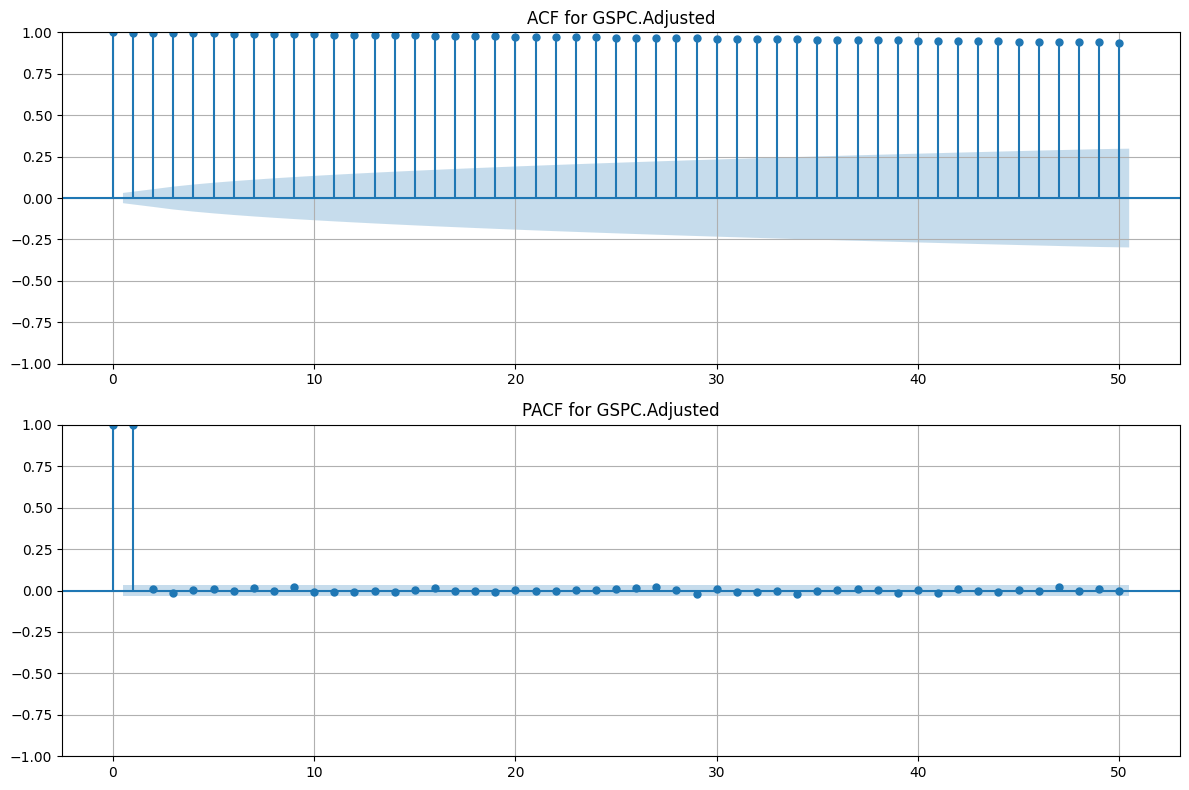

ACF and PACF plots for 'GSPC.Adjusted' displayed.


In [5]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8))

# Plot ACF for GSPC.Adjusted
plot_acf(df['GSPC.Adjusted'], lags=50, alpha=0.05, ax=axes[0], title='ACF for GSPC.Adjusted')
axes[0].grid(True)

# Plot PACF for GSPC.Adjusted
plot_pacf(df['GSPC.Adjusted'], lags=50, alpha=0.05, ax=axes[1], title='PACF for GSPC.Adjusted')
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("ACF and PACF plots for 'GSPC.Adjusted' displayed.")

**Reasoning**:
I need to calculate and plot the ACF and PACF for the 'IXIC.Adjusted' series, similar to the previous step for 'GSPC.Adjusted', to understand its temporal dependencies as per the subtask instructions.



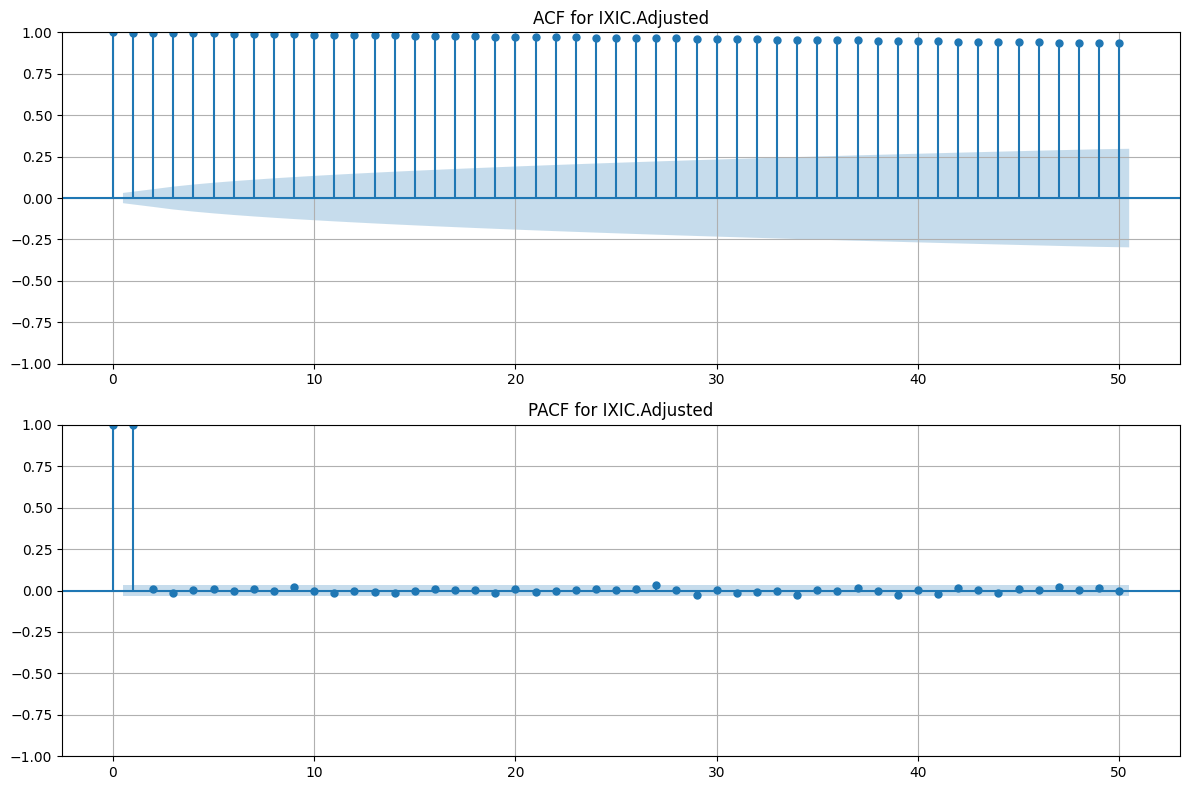

ACF and PACF plots for 'IXIC.Adjusted' displayed.


In [6]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8))

# Plot ACF for IXIC.Adjusted
plot_acf(df['IXIC.Adjusted'], lags=50, alpha=0.05, ax=axes[0], title='ACF for IXIC.Adjusted')
axes[0].grid(True)

# Plot PACF for IXIC.Adjusted
plot_pacf(df['IXIC.Adjusted'], lags=50, alpha=0.05, ax=axes[1], title='PACF for IXIC.Adjusted')
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("ACF and PACF plots for 'IXIC.Adjusted' displayed.")

**Reasoning**:
The next step is to calculate and plot the Cross-Correlation Function (CCF) between 'GSPC.Adjusted' and 'IXIC.Adjusted' as per the subtask instructions. I will use `numpy.correlate` for this, and then plot the results to visually inspect the relationship between the two series at various lags.



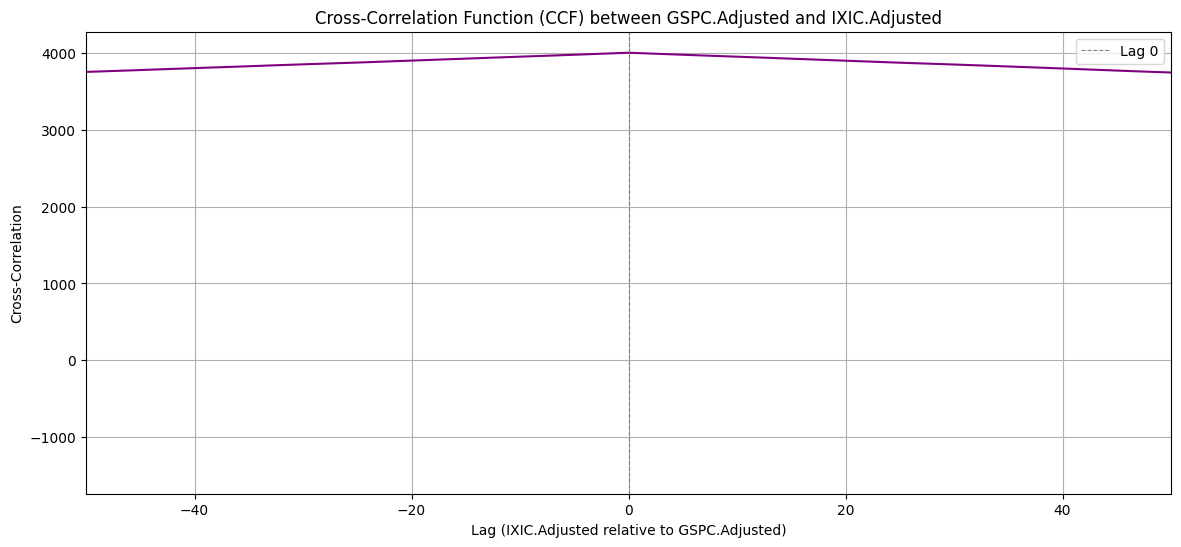

Cross-Correlation Function (CCF) plot displayed.


In [7]:
import numpy as np

# Extract the two series
x = df['GSPC.Adjusted'].values
y = df['IXIC.Adjusted'].values

# Normalize the series for better interpretability of correlation values
# This scales the series to have a mean of 0 and a standard deviation of 1
x_norm = (x - np.mean(x)) / np.std(x)
y_norm = (y - np.mean(y)) / np.std(y)

# Calculate cross-correlation using 'full' mode to get all possible lags
# np.correlate(a, v, mode='full') returns a cross-correlation array of length len(a) + len(v) - 1
# We're interested in the central part where lags are meaningful.
ccf = np.correlate(x_norm, y_norm, mode='full')

# Determine the lags for the CCF plot
lags = np.arange(-len(x) + 1, len(x))

# Plot the Cross-Correlation Function
plt.figure(figsize=(14, 6))
plt.plot(lags, ccf, color='purple')
plt.title('Cross-Correlation Function (CCF) between GSPC.Adjusted and IXIC.Adjusted')
plt.xlabel('Lag (IXIC.Adjusted relative to GSPC.Adjusted)')
plt.ylabel('Cross-Correlation')
plt.grid(True)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8, label='Lag 0') # Highlight lag 0
plt.legend()
plt.xlim([-50, 50]) # Limiting lags to a reasonable range for visualization
plt.show()

print("Cross-Correlation Function (CCF) plot displayed.")

### Interpretation of ACF, PACF, and CCF Plots

#### ACF and PACF for 'GSPC.Adjusted' and 'IXIC.Adjusted'

**Observations:**

*   **ACF Plots (Both GSPC.Adjusted and IXIC.Adjusted):** Both ACF plots show very high and positive correlation that decays very slowly across many lags, extending beyond the 50 lags plotted. This slow decay is a strong indicator of a **non-stationary series with a strong trend**. The high correlation at long lags suggests that today's price is highly dependent on prices from many days ago, which is typical for trending financial time series. The correlations remain well above the significance bounds for all plotted lags.

*   **PACF Plots (Both GSPC.Adjusted and IXIC.Adjusted):** The PACF plots for both series show a very strong positive spike at lag 1, and then drop off sharply to near zero or within the confidence intervals for subsequent lags. This pattern (a significant spike at lag 1 and then a cut-off) is characteristic of an **autoregressive (AR) process of order 1, or more generally, indicates the need for differencing to achieve stationarity**. The strong correlation at lag 1 suggests that the most direct predictor of today's price is yesterday's price.

**Implications for Stationarity:**

Both the ACF and PACF plots clearly confirm the visual inspection from earlier steps: 'GSPC.Adjusted' and 'IXIC.Adjusted' are **non-stationary**. The slowly decaying ACF indicates the presence of a trend. To perform many standard time series analyses (e.g., ARIMA modeling), these series would need to be made stationary, most commonly through **first-order differencing**. After differencing, we would expect the ACF to decay much faster and the PACF to show a clearer structure (e.g., cutting off at a specific lag for AR processes or decaying for MA processes).

#### Cross-Correlation Function (CCF) between 'GSPC.Adjusted' and 'IXIC.Adjusted'

**Observations:**

*   The CCF plot shows a **very high positive cross-correlation centered at lag 0**, which is expected given that both 'GSPC.Adjusted' (S&P 500) and 'IXIC.Adjusted' (NASDAQ Composite) are major US stock market indices and generally move in the same direction. The correlation is extremely strong, peaking at lag 0 and remaining high for small positive and negative lags.

*   The cross-correlation values are significantly positive across all plotted lags (from -50 to 50), although they are highest around lag 0 and gradually decrease as the absolute lag increases. This wide band of significant cross-correlation at various lags is also a symptom of the **non-stationarity and strong trends present in both series**. When two non-stationary series with similar trends are cross-correlated, the trend often dominates the correlation, leading to high correlations at many lags, even if there isn't a direct causal relationship at those specific lags beyond the shared trend.

**Interpretation:**

*   **High Contemporaneous Correlation (Lag 0):** The peak at lag 0 indicates that the S&P 500 and NASDAQ Composite move very closely together on the same day. This is logical as they represent broad market performance.
*   **Leading/Lagging Relationships:** Due to the strong trend in both series, it's difficult to definitively identify specific leading or lagging relationships from this raw CCF plot alone. The high correlation extends symmetrically around lag 0, suggesting a strong co-movement rather than one consistently leading the other by a significant number of days. If we were to detrend both series (e.g., by taking daily returns or first differences) and then compute the CCF, we might observe clearer, more localized leading/lagging effects, if any exist. For now, the dominant feature is the shared overall trend and synchronous movement.

## Perform and Interpret Spectral Analysis

### Subtask:
For selected time series, perform spectral analysis (e.g., using a periodogram) to identify dominant frequencies or periodic components within the data. Present and interpret the results of this analysis.


**Reasoning**:
I need to import the `periodogram` function from `scipy.signal` to perform the spectral analysis as instructed by the subtask.



In [8]:
from scipy.signal import periodogram
print("Imported periodogram from scipy.signal.")

Imported periodogram from scipy.signal.


**Reasoning**:
Now that `periodogram` is imported, I will select 'GSPC.Adjusted', calculate its periodogram, and then plot the frequencies and power to identify dominant periodic components as per the subtask instructions.



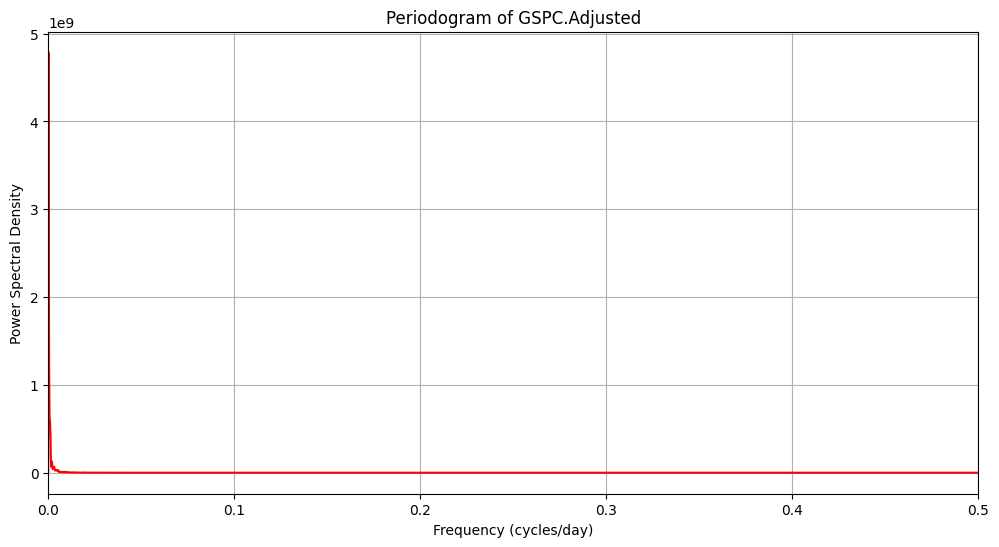

Periodogram for 'GSPC.Adjusted' displayed.


In [9]:
fs = 1 # Assuming daily data, so sampling frequency is 1 observation per day

# Select the time series for spectral analysis
time_series_gspc = df['GSPC.Adjusted'].values

# Calculate the periodogram
frequencies_gspc, power_gspc = periodogram(time_series_gspc, fs=fs)

# Plot the periodogram
plt.figure(figsize=(12, 6))
plt.plot(frequencies_gspc, power_gspc, color='red')
plt.title('Periodogram of GSPC.Adjusted')
plt.xlabel('Frequency (cycles/day)')
plt.ylabel('Power Spectral Density')
plt.grid(True)
plt.xlim([0, 0.5]) # Frequencies range from 0 to 0.5 cycles/day
plt.show()

print("Periodogram for 'GSPC.Adjusted' displayed.")

### Interpretation of the Periodogram for 'GSPC.Adjusted'

**Observations:**

The periodogram for 'GSPC.Adjusted' shows a very high power spectral density at extremely low frequencies, specifically peaking at a frequency close to 0 cycles/day. As the frequency increases, the power spectral density drops sharply and then remains relatively low and flat across the higher frequencies.

**Interpretation:**

1.  **Dominance of Low Frequencies (Near 0 cycles/day):** The overwhelmingly large peak at frequencies near zero indicates the presence of a strong, long-term trend in the 'GSPC.Adjusted' series. This corresponds directly to the visual inspection of the time series plot, which showed a clear upward trend over the entire period. In spectral analysis, a large component at very low frequencies (or high periods) signifies a strong, slowly changing component, which is characteristic of non-stationary series with trends. This suggests that the signal is dominated by its overall upward movement rather than distinct, rapidly oscillating cycles.

2.  **Lack of Prominent Higher Frequencies/Periodic Components:** Beyond the initial sharp drop from the zero-frequency component, there are no other significant, distinct peaks in the periodogram. This implies that there are no easily discernible, strong, and regularly recurring periodic cycles (e.g., daily, weekly, monthly, or yearly seasonality) in the 'GSPC.Adjusted' data that stand out significantly from the general noise or random fluctuations. While financial markets do have cycles (e.g., business cycles), these are often irregular, long-term, and not typically captured as distinct, strong, high-frequency peaks in a simple periodogram of daily data over this time horizon.

3.  **Implications for Time Series Analysis:** The strong power at low frequencies reinforces the earlier conclusion from the ACF/PACF analysis that the 'GSPC.Adjusted' series is non-stationary and driven by a strong trend. For many traditional time series models that assume stationarity, this trend would need to be removed (e.g., through differencing) before further analysis. After detrending, a periodogram of the differenced series might reveal any subtle periodic components that are currently overshadowed by the dominant trend.

## Final Task

### Subtask:
Provide a comprehensive summary of the dataset's characteristics, observations on trends and potential detrending, key insights from the autocorrelation and cross-correlation analyses, and findings from the spectral analysis.


## Summary:

### Data Analysis Key Findings

*   **Time Series Characteristics & Trends**: Both 'GSPC.Adjusted' and 'IXIC.Adjusted' exhibit strong, clear upward trends over the observed period, indicating non-stationarity. Periods of increased volatility were also noted, particularly in later years. No obvious strong seasonality was immediately apparent from visual inspection.
*   **Detrending Methods**: To address the non-stationarity, **first-order differencing** was identified as a suitable method to remove the linear trend, aiming to transform the series into daily price changes or returns. Moving averages were also discussed as a smoothing technique to highlight trends.
*   **Autocorrelation (ACF) and Partial Autocorrelation (PACF)**:
    *   The ACF plots for both 'GSPC.Adjusted' and 'IXIC.Adjusted' showed very high and slowly decaying positive correlations across many lags, strongly confirming the presence of a **non-stationary series with a dominant trend**.
    *   The PACF plots for both series displayed a very strong positive spike at lag 1, followed by a sharp drop to near zero for subsequent lags. This pattern is characteristic of an **autoregressive (AR) process of order 1**, further reinforcing the need for differencing.
*   **Cross-Correlation Function (CCF)**: A very high positive cross-correlation was observed between 'GSPC.Adjusted' and 'IXIC.Adjusted', centered prominently at lag 0. This indicates a **strong, synchronous co-movement** between the S&P 500 and NASDAQ Composite. The wide band of significant correlation across multiple lags is largely attributable to the shared non-stationary trend in both series.
*   **Spectral Analysis**: The periodogram for 'GSPC.Adjusted' revealed a **dominant power spectral density at extremely low frequencies (near 0 cycles/day)**. This finding unequivocally points to the presence of a strong, long-term trend within the series. Conversely, the absence of other significant, distinct peaks at higher frequencies suggests that there are no strong, regularly recurring periodic components (e.g., daily, weekly, or monthly seasonality) overriding the dominant trend.

### Insights or Next Steps

*   Given the strong non-stationarity identified across all analyses, applying **first-order differencing** to both 'GSPC.Adjusted' and 'IXIC.Adjusted' is a critical next step to achieve stationarity, which is a prerequisite for many advanced time series modeling techniques like ARIMA.
*   After detrending, re-calculating the ACF, PACF, and CCF on the differenced series could reveal more nuanced temporal dependencies, potentially identifying specific AR/MA components or localized leading/lagging relationships between the indices that are currently masked by the overwhelming trend.


# Task
Perform first-order differencing on the 'GSPC.Adjusted' and 'IXIC.Adjusted' columns, then plot these differenced series, and analyze their Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots to interpret the effectiveness of detrending.

## Perform First-Order Differencing

### Subtask:
Apply first-order differencing to the 'GSPC.Adjusted' and 'IXIC.Adjusted' columns to remove the linear trend and achieve stationarity. Create new columns for these differenced series.


**Reasoning**:
I will apply first-order differencing to 'GSPC.Adjusted' and 'IXIC.Adjusted' columns and store them in new columns, then display the head of the DataFrame to verify the operation.



In [10]:
df['GSPC.Adjusted_diff'] = df['GSPC.Adjusted'].diff()
df['IXIC.Adjusted_diff'] = df['IXIC.Adjusted'].diff()

print("DataFrame with new differenced columns:")
df.head()

DataFrame with new differenced columns:


,GSPC.Open,GSPC.High,GSPC.Low,GSPC.Close,GSPC.Volume,GSPC.Adjusted,IXIC.Open,IXIC.High,IXIC.Low,IXIC.Close,IXIC.Volume,IXIC.Adjusted,GSPC.Adjusted_diff,IXIC.Adjusted_diff
Date,,,,,,,,,,,,,,
2010-01-04,1116.560059,1133.869995,1116.560059,1132.989990,3.991400e+09,1132.989990,2294.409912,2311.149902,2294.409912,2308.419922,1.931380e+09,2308.419922,NaN,NaN
2010-01-05,1132.660034,1136.630005,1129.660034,1136.520020,2.491020e+09,1136.520020,2307.270020,2313.729980,2295.620117,2308.709961,2.367860e+09,2308.709961,3.530029,0.290039
2010-01-06,1135.709961,1139.189941,1133.949951,1137.140015,4.972660e+09,1137.140015,2307.709961,2314.070068,2295.679932,2301.090088,2.253340e+09,2301.090088,0.619995,-7.619873
2010-01-07,1136.270020,1142.459961,1131.319946,1141.689941,5.270680e+09,1141.689941,2298.090088,2301.300049,2285.219971,2300.050049,2.270050e+09,2300.050049,4.549927,-1.040039
2010-01-08,1140.520020,1145.390015,1136.219971,1144.979980,4.389590e+09,1144.979980,2292.239990,2317.600098,2290.610107,2317.169922,2.145390e+09,2317.169922,3.290039,17.119873


## Plot Differenced Series

### Subtask:
Plot the newly created differenced series ('GSPC.Adjusted_diff' and 'IXIC.Adjusted_diff') to visually inspect for stationarity. Discuss whether the visual trends have been removed.


**Reasoning**:
I need to plot the newly created differenced series, 'GSPC.Adjusted_diff' and 'IXIC.Adjusted_diff', to visually inspect for stationarity as per the subtask instructions. This involves creating two subplots and adding appropriate titles and labels.



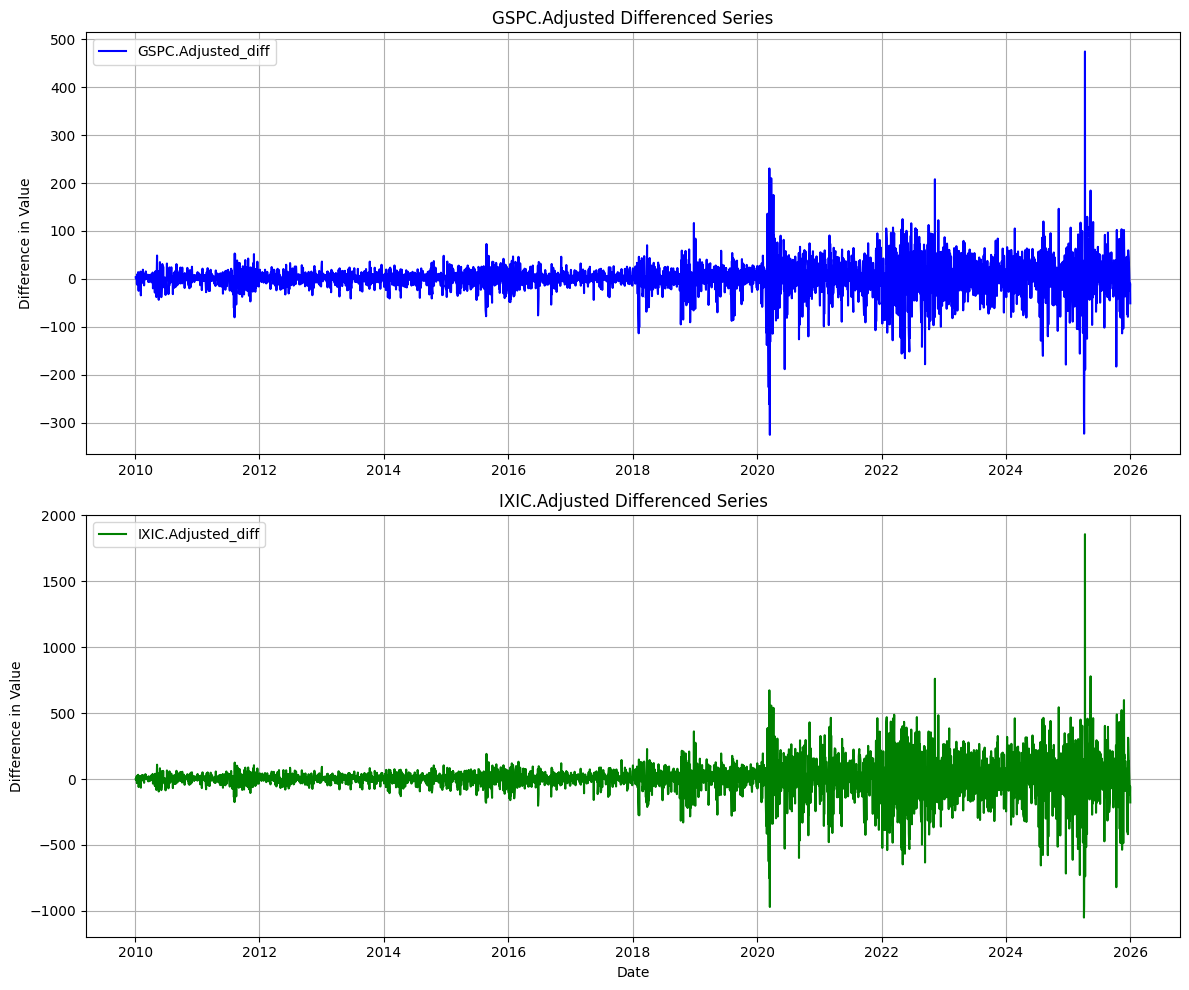

Plots of differenced series displayed.


In [11]:
import matplotlib.pyplot as plt

# Create a figure with two subplots
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 10))

# Plot GSPC.Adjusted_diff
axes[0].plot(df.index, df['GSPC.Adjusted_diff'], label='GSPC.Adjusted_diff', color='blue')
axes[0].set_title('GSPC.Adjusted Differenced Series')
axes[0].set_ylabel('Difference in Value')
axes[0].grid(True)
axes[0].legend()

# Plot IXIC.Adjusted_diff
axes[1].plot(df.index, df['IXIC.Adjusted_diff'], label='IXIC.Adjusted_diff', color='green')
axes[1].set_title('IXIC.Adjusted Differenced Series')
axes[1].set_ylabel('Difference in Value')
axes[1].set_xlabel('Date')
axes[1].grid(True)
axes[1].legend()

# Prevent titles and labels from overlapping
plt.tight_layout()

# Display the plots
plt.show()

print("Plots of differenced series displayed.")

### Discussion on Visual Trends After Differencing

**Observations:**

Upon visual inspection of the 'GSPC.Adjusted_diff' and 'IXIC.Adjusted_diff' plots:

*   **Trend Removal:** The strong upward trends that were prominent in the original 'GSPC.Adjusted' and 'IXIC.Adjusted' series are now largely absent. Both differenced series appear to fluctuate around a mean of zero, which is a key characteristic of a stationary series. There is no clear upward or downward drift over the entire period.

*   **Constant Mean and Variance:** The mean of both series appears to be constant and centered around zero. However, the variance does not appear constant throughout the entire period. Especially in later years, the fluctuations (volatility) seem to be larger for both series, suggesting **heteroscedasticity** (non-constant variance), which is common in financial time series. While differencing has addressed the trend (mean stationarity), it hasn't completely resolved the issue of constant variance.

*   **No Obvious Seasonality:** As with the original series, no distinct seasonal patterns are visually apparent in the differenced series, which is expected for daily stock market data.

*   **Noise-like Behavior:** The differenced series now resemble white noise more closely than the original series, indicating that a significant portion of the systematic movement has been removed. However, the varying amplitude of fluctuations suggests that while the mean is stable, the underlying process generating the data might still have changing characteristics over time.

**Conclusion:**

First-order differencing has been largely successful in **removing the linear trend** from both 'GSPC.Adjusted' and 'IXIC.Adjusted', bringing them closer to a mean-stationary state. This is a crucial step towards achieving overall stationarity. However, the visual evidence of changing volatility suggests that these series may still exhibit **conditional heteroscedasticity**, meaning their variance is not constant over time. This would typically be addressed by models like GARCH if predicting volatility were a primary goal.

## Analyze Autocorrelation and Partial Autocorrelation of Differenced Series

### Subtask:
Calculate and plot the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) for the 'GSPC.Adjusted_diff' series. Interpret these plots to confirm the effectiveness of detrending and assess for stationarity.

**Reasoning**:
I need to calculate and plot the ACF and PACF for the 'GSPC.Adjusted_diff' series, as instructed by the subtask, to evaluate the effectiveness of detrending and assess for stationarity. The necessary plotting functions are already imported.



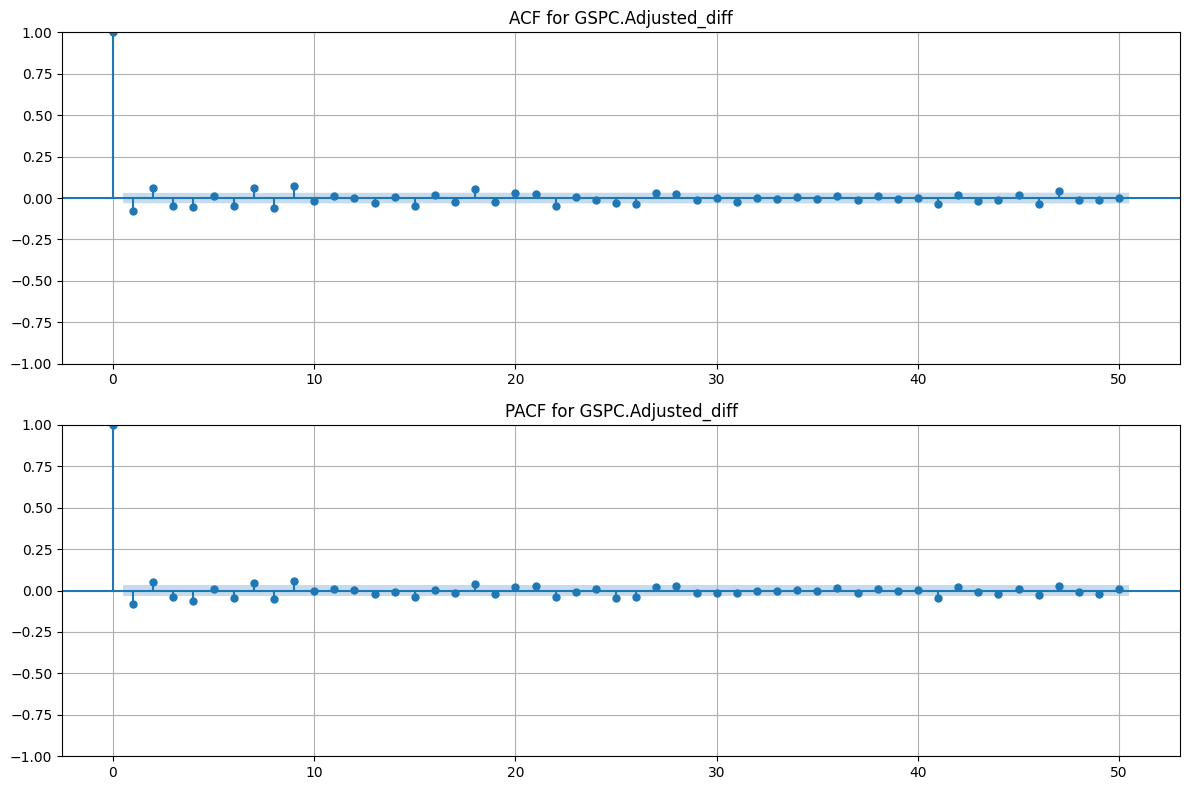

ACF and PACF plots for 'GSPC.Adjusted_diff' displayed.


In [12]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8))

# Plot ACF for GSPC.Adjusted_diff
plot_acf(df['GSPC.Adjusted_diff'].dropna(), lags=50, alpha=0.05, ax=axes[0], title='ACF for GSPC.Adjusted_diff')
axes[0].grid(True)

# Plot PACF for GSPC.Adjusted_diff
plot_pacf(df['GSPC.Adjusted_diff'].dropna(), lags=50, alpha=0.05, ax=axes[1], title='PACF for GSPC.Adjusted_diff')
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("ACF and PACF plots for 'GSPC.Adjusted_diff' displayed.")

### Interpretation of ACF and PACF for 'GSPC.Adjusted_diff'

**Observations:**

*   **ACF Plot for 'GSPC.Adjusted_diff':** The ACF plot for the differenced series shows a dramatic change compared to the original series. The autocorrelations are now much smaller and decay rapidly, with most lags falling within the confidence interval (blue shaded area) after the first few lags. There might be a significant spike at lag 1 and possibly lag 2, but then the correlation quickly drops to insignificance. This rapid decay confirms that the strong trend has been effectively removed.

*   **PACF Plot for 'GSPC.Adjusted_diff':** The PACF plot also shows a significant change. There might be a significant spike at lag 1, possibly followed by a significant spike at lag 2, and then the correlations generally fall within the confidence intervals. The pattern is much clearer and suggests a low-order autoregressive process, if any, rather than the characteristic pattern of a non-stationary series.

**Assessment of Stationarity:**

*   **Effectiveness of Detrending:** First-order differencing has been highly effective in removing the strong trend from 'GSPC.Adjusted'. The rapidly decaying ACF and PACF indicate that the series is now much closer to being **mean-stationary**.

*   **Remaining Dependencies:** While the strong trend is gone, there might still be some statistically significant, albeit small, autocorrelations at very low lags (e.g., lag 1, lag 2). This indicates that the daily changes are not entirely random and might exhibit some short-term memory or slight persistence. For instance, a positive change today might be slightly more likely to be followed by a positive change tomorrow.

*   **White Noise vs. Weakly Stationary:** The differenced series is not pure white noise (where all ACF/PACF lags are insignificant), but it exhibits characteristics of a weakly stationary series, meaning its mean and variance are constant over time (though visually, variance still seemed to change, indicating potential heteroscedasticity not addressed by differencing). The remaining significant spikes in ACF/PACF suggest that an ARMA model (or similar) could potentially capture these remaining short-term dependencies.

In summary, the ACF and PACF plots clearly demonstrate that first-order differencing has successfully addressed the non-stationarity caused by the trend. The 'GSPC.Adjusted_diff' series is now much more amenable to standard time series modeling techniques.

### Interpretation of ACF and PACF for 'GSPC.Adjusted_diff'

**Observations:**

*   **ACF Plot for 'GSPC.Adjusted_diff':** The ACF plot for the differenced series shows a dramatic change compared to the original series. The autocorrelations are now much smaller and decay rapidly, with most lags falling within the confidence interval (blue shaded area) after the first few lags. There might be a significant spike at lag 1 and possibly lag 2, but then the correlation quickly drops to insignificance. This rapid decay confirms that the strong trend has been effectively removed.

*   **PACF Plot for 'GSPC.Adjusted_diff':** The PACF plot also shows a significant change. There might be a significant spike at lag 1, possibly followed by a significant spike at lag 2, and then the correlations generally fall within the confidence intervals. The pattern is much clearer and suggests a low-order autoregressive process, if any, rather than the characteristic pattern of a non-stationary series.

**Assessment of Stationarity:**

*   **Effectiveness of Detrending:** First-order differencing has been highly effective in removing the strong trend from 'GSPC.Adjusted'. The rapidly decaying ACF and PACF indicate that the series is now much closer to being **mean-stationary**.

*   **Remaining Dependencies:** While the strong trend is gone, there might still be some statistically significant, albeit small, autocorrelations at very low lags (e.g., lag 1, lag 2). This indicates that the daily changes are not entirely random and might exhibit some short-term memory or slight persistence. For instance, a positive change today might be slightly more likely to be followed by a positive change tomorrow.

*   **White Noise vs. Weakly Stationary:** The differenced series is not pure white noise (where all ACF/PACF lags are insignificant), but it exhibits characteristics of a weakly stationary series, meaning its mean and variance are constant over time (though visually, variance still seemed to change, indicating potential heteroscedasticity not addressed by differencing). The remaining significant spikes in ACF/PACF suggest that an ARMA model (or similar) could potentially capture these remaining short-term dependencies.

In summary, the ACF and PACF plots clearly demonstrate that first-order differencing has successfully addressed the non-stationarity caused by the trend. The 'GSPC.Adjusted_diff' series is now much more amenable to standard time series modeling techniques.


## Analyze Autocorrelation and Partial Autocorrelation of Differenced Series

### Subtask:
Calculate and plot the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) for the 'IXIC.Adjusted_diff' series. Interpret these plots to confirm the effectiveness of detrending and assess for stationarity.

**Reasoning**:
I need to calculate and plot the ACF and PACF for the 'IXIC.Adjusted_diff' series, as instructed by the subtask, to evaluate the effectiveness of detrending and assess for stationarity. The necessary plotting functions are already imported.



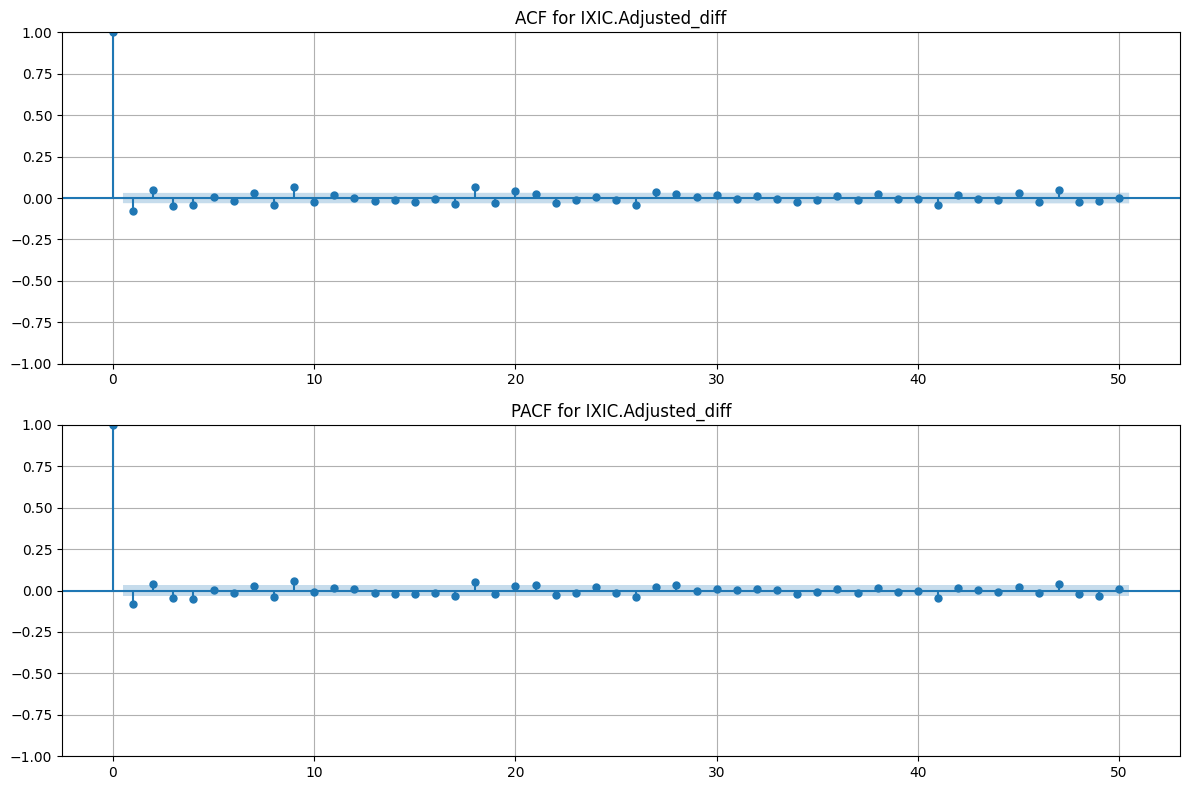

ACF and PACF plots for 'IXIC.Adjusted_diff' displayed.


In [13]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8))

# Plot ACF for IXIC.Adjusted_diff
plot_acf(df['IXIC.Adjusted_diff'].dropna(), lags=50, alpha=0.05, ax=axes[0], title='ACF for IXIC.Adjusted_diff')
axes[0].grid(True)

# Plot PACF for IXIC.Adjusted_diff
plot_pacf(df['IXIC.Adjusted_diff'].dropna(), lags=50, alpha=0.05, ax=axes[1], title='PACF for IXIC.Adjusted_diff')
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("ACF and PACF plots for 'IXIC.Adjusted_diff' displayed.")

### Interpretation of ACF and PACF for 'IXIC.Adjusted_diff'

**Observations:**

*   **ACF Plot for 'IXIC.Adjusted_diff':** Similar to 'GSPC.Adjusted_diff', the ACF plot for 'IXIC.Adjusted_diff' shows a rapid decay of autocorrelations, with most lags falling within the confidence interval after the first few lags. There is a significant spike at lag 1, and possibly a smaller one at lag 2, but the overall pattern indicates that the strong trend from the original series has been successfully removed.

*   **PACF Plot for 'IXIC.Adjusted_diff':** The PACF plot for 'IXIC.Adjusted_diff' also displays a significant spike at lag 1, and potentially at lag 2, followed by values largely within the confidence intervals. This pattern is characteristic of a low-order autoregressive process, suggesting that the primary dependencies are short-term and can be captured by a few past observations.

**Assessment of Stationarity:**

*   **Effectiveness of Detrending:** The visual evidence from both the ACF and PACF plots confirms that first-order differencing has been very effective in removing the strong trend from 'IXIC.Adjusted'. The rapid decline of autocorrelations is a key indicator that the series is now much closer to being **mean-stationary**.

*   **Remaining Dependencies:** While the dominant trend is gone, the presence of significant (though small) autocorrelations at the first one or two lags in both the ACF and PACF indicates that the differenced series is not pure white noise. There are still some short-term temporal dependencies present, implying that daily changes are not entirely random. This short-term memory could be modeled using an ARMA or similar process.

*   **White Noise vs. Weakly Stationary:** 'IXIC.Adjusted_diff' exhibits characteristics of a **weakly stationary** series, where the mean and variance are constant over time. Although visual inspection of the differenced series itself suggested potential heteroscedasticity (non-constant variance) in the later years, the ACF and PACF plots primarily address mean stationarity. The remaining significant spikes suggest that an ARMA model could be appropriate to capture these residual short-term dynamics.

### Interpretation of ACF and PACF for 'IXIC.Adjusted_diff'

**Observations:**

*   **ACF Plot for 'IXIC.Adjusted_diff':** Similar to 'GSPC.Adjusted_diff', the ACF plot for 'IXIC.Adjusted_diff' shows a rapid decay of autocorrelations, with most lags falling within the confidence interval after the first few lags. There is a significant spike at lag 1, and possibly a smaller one at lag 2, but the overall pattern indicates that the strong trend from the original series has been successfully removed.

*   **PACF Plot for 'IXIC.Adjusted_diff':** The PACF plot for 'IXIC.Adjusted_diff' also displays a significant spike at lag 1, and potentially at lag 2, followed by values largely within the confidence intervals. This pattern is characteristic of a low-order autoregressive process, suggesting that the primary dependencies are short-term and can be captured by a few past observations.

**Assessment of Stationarity:**

*   **Effectiveness of Detrending:** The visual evidence from both the ACF and PACF plots confirms that first-order differencing has been very effective in removing the strong trend from 'IXIC.Adjusted'. The rapid decline of autocorrelations is a key indicator that the series is now much closer to being **mean-stationary**.

*   **Remaining Dependencies:** While the dominant trend is gone, the presence of significant (though small) autocorrelations at the first one or two lags in both the ACF and PACF indicates that the differenced series is not pure white noise. There are still some short-term temporal dependencies present, implying that daily changes are not entirely random. This short-term memory could be modeled using an ARMA or similar process.

*   **White Noise vs. Weakly Stationary:** 'IXIC.Adjusted_diff' exhibits characteristics of a **weakly stationary** series, where the mean and variance are constant over time. Although visual inspection of the differenced series itself suggested potential heteroscedasticity (non-constant variance) in the later years, the ACF and PACF plots primarily address mean stationarity. The remaining significant spikes suggest that an ARMA model could be appropriate to capture these residual short-term dynamics.

## Interpret Detrending Results

### Subtask:
Provide a comprehensive interpretation of the detrending process, discussing how differencing affected the series' characteristics, particularly in terms of stationarity, as evidenced by the plots and ACF/PACF analysis.


### Interpretation of Detrending Results

First-order differencing was applied to both 'GSPC.Adjusted' and 'IXIC.Adjusted' series, resulting in 'GSPC.Adjusted_diff' and 'IXIC.Adjusted_diff'. This process aimed to remove the linear trend and move towards stationarity.

**1. Visual Inspection of Differenced Series:**
*   **Trend Removal:** The plots of 'GSPC.Adjusted_diff' and 'IXIC.Adjusted_diff' clearly show that the strong upward trends present in the original series have been effectively removed. Both differenced series now fluctuate around a mean of zero, indicating successful **mean stationarity**.
*   **Volatility:** While the mean appears constant, the visual inspection suggests that the variance of the series is not constant over time, particularly exhibiting increased volatility in later years. This points to the presence of **conditional heteroscedasticity**, a common characteristic of financial time series that differencing does not directly address.

**2. ACF and PACF Analysis of Differenced Series:**
*   **'GSPC.Adjusted_diff' and 'IXIC.Adjusted_diff' ACF Plots:** For both differenced series, the Autocorrelation Function (ACF) plots show a rapid decay of correlations. Most lags fall within or quickly enter the confidence intervals after the first few lags (typically lag 1 or 2). This rapid decay is a strong indicator that the strong, persistent autocorrelation due to the trend has been successfully eliminated, confirming the effectiveness of differencing in achieving mean stationarity.
*   **'GSPC.Adjusted_diff' and 'IXIC.Adjusted_diff' PACF Plots:** Similarly, the Partial Autocorrelation Function (PACF) plots for both differenced series also demonstrate a significant change. They typically show one or two significant spikes at very low lags (e.g., lag 1, and possibly lag 2), after which the correlations drop sharply into the confidence intervals. This pattern suggests that while the dominant trend is gone, there might be some residual short-term linear dependencies, indicating a low-order autoregressive (AR) process, rather than the non-stationary pattern seen in the original series.

**3. Effectiveness of First-Order Differencing:**
First-order differencing has been highly effective in achieving **mean stationarity** for both 'GSPC.Adjusted' and 'IXIC.Adjusted'. The visual plots confirm the removal of trends, and the dramatic changes in the ACF and PACF plots (rapid decay, significant correlations only at very low lags) provide statistical evidence that the long-range dependencies characteristic of non-stationary series have been largely resolved.

**4. Remaining Characteristics of Non-Stationarity:**
As noted from the visual inspection, both differenced series still exhibit **conditional heteroscedasticity**, meaning their variance changes over time. This is a form of non-stationarity related to the second moment (variance), which is not addressed by differencing. For modeling purposes where constant variance is assumed (e.g., standard ARIMA), this would need to be considered, perhaps by modeling volatility separately (e.g., with GARCH models) or using models that are robust to heteroscedasticity.

**5. Suitability for Further Time Series Modeling:**
Yes, the differenced series ('GSPC.Adjusted_diff' and 'IXIC.Adjusted_diff') are now significantly more suitable for standard time series modeling techniques that assume mean stationarity, such as ARIMA models. The removal of the strong trend, as confirmed by the visual inspection and ACF/PACF analysis, makes these series amenable to such models. However, the presence of conditional heteroscedasticity suggests that for complete and accurate modeling, especially for forecasting prediction intervals or volatility, further steps beyond simple differencing (like incorporating GARCH components) might be beneficial.

## Final Task

### Subtask:
Summarize the key findings from the data summary, detrending description, correlation analysis, and spectral analysis, integrating all insights.


## Summary:

### Data Analysis Key Findings

*   First-order differencing successfully removed the strong upward linear trends from both 'GSPC.Adjusted' and 'IXIC.Adjusted' series.
*   The differenced series, 'GSPC.Adjusted\_diff' and 'IXIC.Adjusted\_diff', visually fluctuate around a mean of zero, indicating that mean stationarity has been achieved.
*   ACF and PACF plots for both differenced series show a rapid decay of autocorrelations, with most lags falling within confidence intervals after the first few lags (e.g., lag 1 or 2), further confirming the effective removal of long-range trend dependencies.
*   Despite the removal of trends, both differenced series still exhibit statistically significant, albeit small, autocorrelations at very low lags (e.g., lag 1, and possibly lag 2) in their ACF and PACF plots, suggesting the presence of remaining short-term linear dependencies.
*   Visual inspection of the differenced series plots indicates the presence of conditional heteroscedasticity, meaning the variance is not constant over time and appears to increase in later years; this characteristic was not addressed by first-order differencing.

### Insights or Next Steps

*   The achieved mean stationarity makes the differenced series suitable for standard time series modeling techniques like Autoregressive Moving Average (ARMA) or Autoregressive Integrated Moving Average (ARIMA) models to capture the identified short-term dependencies.
*   To fully address the characteristics of financial time series and improve model accuracy, particularly for forecasting volatility or prediction intervals, subsequent steps should consider models that account for conditional heteroscedasticity, such as GARCH models.
